<a href="https://colab.research.google.com/github/rualbonline-web/Cafe-Sales/blob/main/Copy_of_Pandas_lesson_34_03_11_26_training_project_cafe_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ☕ Робочий зошит: очищення даних та EDA
## Датасет: продажі кафе («брудні» дані)

У цьому зошиті ви пройдете повний шлях аналітика: від «брудного» файлу з помилками до чистої таблиці, графіків і висновків для власника кафе.

**Як працювати:**
- Запускайте клітинки **по черзі**, зверху вниз.
- Пишіть код у клітинках з коментарем `# Ваш код тут`.
- У кожному завданні є три частини: **що зробити**, **навіщо** це потрібно і **команди**, які знадобляться.
- Висновки записуйте в клітинки з позначкою ✏️. Пишіть їх своїми словами і з конкретними числами.
- Розв'язки всіх завдань зібрані в **останній клітинці** блокнота. Зазирайте туди, лише якщо справді застрягли. Якщо щось зламалося, можна запустити її: вона заново виконає всі кроки й створить усі змінні.

**Структура:**
- **Частина 1.** Первинний огляд: що не так з даними.
- **Частина 2.** Очищення: виправляємо типи, відновлюємо пропуски, додаємо нові стовпці.
- **Частина 3.** EDA: товари, оплата, час, викиди, зв'язки між числами.
- **Частина 4.** Підсумковий звіт і рекомендації.

## Про дані

Датасет **Cafe Sales — Dirty Data for Cleaning Training** (Kaggle) містить 10 000 продажів кафе за 2023 рік. Дані синтетичні й навмисно «зіпсовані»: у них є пропуски, слова `ERROR` і `UNKNOWN` замість значень та інші проблеми.

| Стовпець | Що містить |
|---|---|
| `Transaction ID` | унікальний номер продажу |
| `Item` | товар: кава, чай, торт тощо |
| `Quantity` | кількість одиниць товару |
| `Price Per Unit` | ціна однієї одиниці, $ |
| `Total Spent` | сума продажу, $ (= кількість × ціна) |
| `Payment Method` | спосіб оплати |
| `Location` | де купили: у закладі чи на виніс |
| `Transaction Date` | дата продажу |

## ⚙️ Підготовка
Запустіть клітинку нижче. Вона підключає бібліотеки, задає шлях до файлу з даними і стиль графіків.

💡 Якщо посилання на файл не відкривається, завантажте `dirty_cafe_sales.csv` у панель 📁 ліворуч і замініть значення `FILE_IN` на `"dirty_cafe_sales.csv"`.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Звідки читаємо «брудні» дані і куди збережемо чисті
FILE_IN = "https://raw.githubusercontent.com/rualbonline-web/Cafe-Sales/refs/heads/main/dirty_cafe_sales.csv"
FILE_OUT = "cafe_sales_clean.csv"

# Єдиний стиль для всіх графіків
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

print("Ready!")

Ready!


---
# Частина 1. Первинний огляд

Перш ніж щось виправляти, треба зрозуміти, **що саме** не так з даними. У цій частині ми нічого не змінюємо по суті, лише дивимося й рахуємо.

## Завдання 1.1. Завантаження і перший погляд

**Що зробити:**
1. Прочитайте файл `FILE_IN` у змінну `df_original`.
2. Зробіть копію в змінну `df`. Далі працюйте лише з `df`.
3. Виведіть розмір таблиці (рядки і стовпці), перші 10 рядків і `info()`.

**Навіщо:** `df_original` лишається незмінним «зліпком» вихідних даних. Наприкінці ми порівняємо з ним результат і порахуємо, скільки рядків втратили під час очищення. А якщо щось піде не так, завжди можна почати з чистого аркуша.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `pd.read_csv(FILE_IN)` | прочитати CSV-файл у таблицю |
| `df.copy()` | незалежна копія таблиці |
| `df.shape` | (кількість рядків, кількість стовпців) |
| `df.head(10)` | перші 10 рядків |
| `df.info()` | типи стовпців і кількість заповнених значень |

In [5]:
# Завантажуємо датасет. Спершу використовуємо URL із завдання,
# далі — публічне дзеркало того самого Kaggle-набору або локальний файл.
file_sources = [
    FILE_IN,
    "https://raw.githubusercontent.com/Elthiero/Cafe-Sales-kaggle/main/dirty_cafe_sales.csv",
    "dirty_cafe_sales.csv",
]
df_original = None
for source in dict.fromkeys(file_sources):
    try:
        candidate = pd.read_csv(source)
        expected_cols = {"Transaction ID", "Item", "Quantity", "Price Per Unit",
                         "Total Spent", "Payment Method", "Location", "Transaction Date"}
        if not expected_cols.issubset(candidate.columns):
            raise ValueError("У файлі бракує стовпців з умови завдання")
        df_original = candidate
        print("Джерело даних:", source)
        break
    except Exception as e:
        print("Не вдалося прочитати:", source, "(", type(e).__name__, ")")
if df_original is None:
    raise FileNotFoundError("Завантажте dirty_cafe_sales.csv у Colab і запустіть клітинку знову.")

df = df_original.copy()
print("Розмір:", df.shape[0], "рядків ×", df.shape[1], "стовпців")
display(df.head(10))
df.info()

Джерело даних: https://raw.githubusercontent.com/rualbonline-web/Cafe-Sales/refs/heads/main/dirty_cafe_sales.csv
Розмір: 10000 рядків × 8 стовпців


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


✏️ Спостереження (1.1). Quantity, Price Per Unit і Total Spent мають бути числовими, а Transaction Date — датою. Через ERROR, UNKNOWN та інші порожні або невалідні записи pandas може зчитати їх як object. Фактичні типи для цього файла показано в df.info() вище.

## Завдання 1.2. Що за «сміття» в даних?

**Що зробити:**
1. Для стовпців `Item`, `Payment Method` і `Location` виведіть усі значення з кількістю, **включно з пропусками**.
2. Для стовпців `Quantity`, `Price Per Unit` і `Total Spent` знайдіть усі значення, які **не є числами** (без урахування порожніх клітинок), і виведіть їх унікальні варіанти. Те саме зробіть для `Transaction Date`, тільки шукайте значення, які не є датами.
3. Порахуйте, скільки разів у кожному стовпці трапляються слова `"ERROR"` і `"UNKNOWN"`.

**Навіщо:** далі ми перетворимо стовпці на числа командою `pd.to_numeric(..., errors="coerce")`. Вона **мовчки** перетворює на пропуск усе, що не схоже на число. Якщо в стовпці трапиться, скажімо, `"4,5"` або `"$4"`, ми втратимо значення, яке можна було виправити. Тому спершу дивимося, що саме там записано.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df["col"].value_counts(dropna=False)` | кількість кожного значення разом з пропусками (`NaN`) |
| `pd.to_numeric(df["col"], errors="coerce")` | текст → число; те, що не є числом, стає `NaN` |
| `pd.to_datetime(df["col"], errors="coerce")` | текст → дата; те, що не є датою, стає `NaT` |
| `.isna()` / `.notna()` | `True`, де значення порожнє / заповнене |
| `df.loc[умова, "col"].unique()` | унікальні значення стовпця в рядках, що відповідають умові |
| `df.isin(["ERROR", "UNKNOWN"]).sum()` | скільки разів ці слова трапляються в кожному стовпці |

💡 Значення, яке «не є числом», — це значення, яке **було** заповнене, але після `pd.to_numeric` стало порожнім. Поєднайте дві умови через `&`.

In [6]:
for col in ["Item", "Payment Method", "Location"]:
    display(df[col].value_counts(dropna=False))

for col in ["Quantity", "Price Per Unit", "Total Spent"]:
    converted = pd.to_numeric(df[col], errors="coerce")
    print(col, "->", df.loc[converted.isna() & df[col].notna(), col].unique())

converted = pd.to_datetime(df["Transaction Date"], errors="coerce")
print("Transaction Date ->", df.loc[converted.isna() & df["Transaction Date"].notna(), "Transaction Date"].unique())

display(df.isin(["ERROR", "UNKNOWN"]).sum())

print("Оригінальні порожні клітинки:")
display(df.isna().sum())

,count
Item,
Juice,1171
Coffee,1165
Salad,1148
Cake,1139
Sandwich,1131
Smoothie,1096
Cookie,1092
Tea,1089
UNKNOWN,344


,count
Payment Method,
NaN,2579
Digital Wallet,2291
Credit Card,2273
Cash,2258
ERROR,306
UNKNOWN,293


,count
Location,
NaN,3265
Takeaway,3022
In-store,3017
ERROR,358
UNKNOWN,338


Quantity -> ['ERROR' 'UNKNOWN']
Price Per Unit -> ['ERROR' 'UNKNOWN']
Total Spent -> ['ERROR' 'UNKNOWN']
Transaction Date -> ['ERROR' 'UNKNOWN']


,0
Transaction ID,0
Item,636
Quantity,341
Price Per Unit,354
Total Spent,329
Payment Method,599
Location,696
Transaction Date,301


Оригінальні порожні клітинки:


,0
Transaction ID,0
Item,333
Quantity,138
Price Per Unit,179
Total Spent,173
Payment Method,2579
Location,3265
Transaction Date,159


✏️ Спостереження (1.2). Нечислові маркери в початковому наборі — ERROR і UNKNOWN; їх не варто трактувати як нулі. Які саме значення трапляються у кожному стовпці, показує перевірка через .unique() вище. Чисел з комою або символом $ у довідковому розв'язку не описано; якщо вони з'являться в іншій версії CSV, їх потрібно обробляти окремо.

## Завдання 1.3. Дублікати

**Що зробити:**
1. Порахуйте повні дублікати рядків.
2. Порахуйте, чи повторюються номери продажів у `Transaction ID`.
3. Видаліть повні дублікати й виведіть кількість рядків після цього.

**Навіщо:** якщо один продаж записано двічі, виторг завищиться. Перевірка `Transaction ID` важлива окремо: номер має бути унікальним, і повтор номера з різними даними означав би серйозну помилку в обліку.

💡 Отримати **0** — теж результат. Це означає, що проблеми немає, і це варто записати у висновок.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.duplicated().sum()` | кількість рядків, що повністю повторюють попередній |
| `df["col"].duplicated().sum()` | кількість повторів у одному стовпці |
| `df.drop_duplicates()` | таблиця без повних дублікатів |

In [7]:
print("Full duplicates:", df.duplicated().sum())
print("Repeated transaction IDs:", df["Transaction ID"].duplicated().sum())
df = df.drop_duplicates().copy()
print("Rows after removing duplicates:", len(df))

Full duplicates: 0
Repeated transaction IDs: 0
Rows after removing duplicates: 10000


## Завдання 1.4. Огляд пропусків

**Що зробити:**
1. Замініть у всій таблиці слова `"ERROR"` і `"UNKNOWN"` на `np.nan`.
2. Порахуйте пропуски в кожному стовпці: кількість і відсоток від усіх рядків. Зберіть результат у таблицю `missing_report` зі стовпцями `missing` і `pct` і покажіть лише стовпці, де пропуски є, від найбільшого відсотка до найменшого.
3. Побудуйте горизонтальний стовпчиковий графік відсотка пропусків з підписами значень.

**Навіщо:** `ERROR` і `UNKNOWN` — це ті самі пропуски, просто «замасковані». Поки вони записані словами, pandas вважає їх звичайними значеннями і не рахує як пропуски. Огляд показує, які стовпці постраждали найбільше. Далі для кожного треба вирішити: **відновити** значення (якщо воно пов'язане з іншими стовпцями формулою), **заповнити** позначкою або **видалити** рядок.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.replace(["ERROR", "UNKNOWN"], np.nan)` | замінити ці значення на пропуск у всій таблиці |
| `df.isna().sum()` | кількість пропусків у кожному стовпці |
| `pd.DataFrame({"missing": ..., "pct": ...})` | зібрати кілька Series в одну таблицю |
| `.sort_values(ascending=False)` | сортування від більшого до меншого |
| `series.plot(kind="barh")` | горизонтальні стовпчики |
| `ax.bar_label(ax.containers[0], fmt="%.1f%%")` | підписи значень на стовпчиках у відсотках |

,missing,pct
Location,3961,39.6
Payment Method,3178,31.8
Item,969,9.7
Price Per Unit,533,5.3
Total Spent,502,5.0
Quantity,479,4.8
Transaction Date,460,4.6


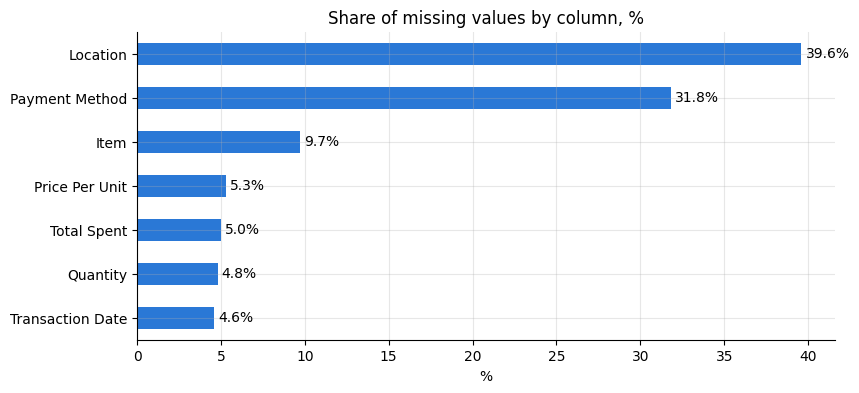

Найбільше пропусків у: Location (39.6%)


In [8]:
df = df.replace(["ERROR", "UNKNOWN"], np.nan)

missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_report = pd.DataFrame({"missing": missing, "pct": missing_pct})
display(missing_report[missing_report["missing"] > 0].sort_values("pct", ascending=False))

ax = missing_pct[missing_pct > 0].sort_values().plot(kind="barh", color="#2a78d6")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Share of missing values by column, %")
plt.xlabel("%")
plt.show()

print("Найбільше пропусків у:", missing_report["pct"].idxmax(), f"({missing_report['pct'].max():.1f}%)")

✏️ Спостереження (1.4). Найбільші пропуски та їх відсотки наведено у таблиці missing_report і на графіку. Числа (quantity, price_per_unit, total_spent) частково відновлюємо з формули або меню. transaction_date, payment_method і location з інших полів надійно не відновити.

---
# Частина 2. Очищення даних

Головне правило очищення: **спочатку відновлюємо те, що можна порахувати точно, і лише потім заповнюємо решту**. Кожне вигадане значення спотворює аналіз, тому вигадуємо якомога менше.

## Завдання 2.1. Назви стовпців

**Що зробити:** перейменуйте всі стовпці у формат `snake_case`: малі літери, слова через підкреслення. Наприклад, `Price Per Unit` → `price_per_unit`. Зробіть це **одним рядком** для всіх стовпців одразу і виведіть нові назви.

**Навіщо:** у назвах з пробілами й великими літерами легко помилитися, а до стовпців без пробілів можна звертатися ще й через крапку (`df.price_per_unit`).

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.columns.str.lower()` | усі назви малими літерами |
| `.str.replace(" ", "_")` | замінити пробіли на підкреслення |
| `df.columns = ...` | записати нові назви |

In [9]:
df.columns = df.columns.str.lower().str.replace(" ", "_")
print(list(df.columns))

['transaction_id', 'item', 'quantity', 'price_per_unit', 'total_spent', 'payment_method', 'location', 'transaction_date']


## Завдання 2.2. Правильні типи даних

**Що зробити:**
1. Перетворіть `quantity`, `price_per_unit` і `total_spent` на числа, а `transaction_date` на дату. Використайте `errors="coerce"`.
2. Перевірте типи через `info()` і знову порахуйте пропуски в кожному стовпці.

**Навіщо:** відновлювати значення ми будемо за формулами (сума = кількість × ціна), а рахувати можна лише з числами. Тому типи виправляємо **до** заповнення пропусків.

**Перевірка:** кількість пропусків має збігтися з тим, що ви бачили в завданні 1.4. Якщо пропусків стало більше, отже, під час конвертації зникли значення, які не були ні `ERROR`, ні `UNKNOWN`. Поверніться до завдання 1.2 і подивіться, що це за значення.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `pd.to_numeric(df["col"], errors="coerce")` | текст → число |
| `pd.to_datetime(df["col"], errors="coerce")` | текст → дата |
| `for col in [...]:` | повторити ту саму дію для кількох стовпців |

In [10]:
for col in ["quantity", "price_per_unit", "total_spent"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")

df.info()
display(df.isna().sum())

print("Пропусків після конвертації стало більше (за стовпцями):")
display((df.isna().sum() - missing_report["missing"]).loc[lambda s: s != 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    10000 non-null  object        
 1   item              9031 non-null   object        
 2   quantity          9521 non-null   float64       
 3   price_per_unit    9467 non-null   float64       
 4   total_spent       9498 non-null   float64       
 5   payment_method    6822 non-null   object        
 6   location          6039 non-null   object        
 7   transaction_date  9540 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 625.1+ KB


,0
transaction_id,0
item,969
quantity,479
price_per_unit,533
total_spent,502
payment_method,3178
location,3961
transaction_date,460


Пропусків після конвертації стало більше (за стовпцями):


,0
Item,NaN
Location,NaN
Payment Method,NaN
Price Per Unit,NaN
Quantity,NaN
Total Spent,NaN
Transaction Date,NaN
Transaction ID,NaN
item,NaN
location,NaN


## Завдання 2.3. Відновлюємо числа точно

Між числовими стовпцями є жорсткий зв'язок: **сума = кількість × ціна**. А ще в меню кафе кожен товар має фіксовану ціну. Отже, багато пропусків можна не вгадувати, а **порахувати**.

**Що зробити:**
1. Перевірте, що кожен товар справді має **одну** ціну: порахуйте кількість різних цін для кожного товару.
2. Створіть словник `price_of_item` «товар → ціна».
3. Відновіть пропуски в такому порядку, щоразу виводячи, скільки рядків заповнено:
   - а) **ціна** за товаром, де товар відомий, а ціна ні;
   - б) **ціна** = сума / кількість, де ціна досі порожня, а сума й кількість відомі;
   - в) **кількість** = сума / ціна (округліть до цілого), де кількість порожня;
   - г) **сума** = кількість × ціна, де сума порожня.
4. Перевірте, що в усіх рядках, де заповнені всі три числа, кількість × ціна дорівнює сумі (порівнюйте значення, округлені до 2 знаків). Виведіть, скільки пропусків лишилося в трьох числових стовпцях.

**Навіщо:** це не здогадки, а математика, тож такі значення так само надійні, як оригінальні. Порядок важливий: спочатку ціна, бо без неї не порахувати ні кількість, ні суму.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.groupby("item")["price_per_unit"].nunique()` | скільки різних цін має кожен товар |
| `df.groupby("item")["price_per_unit"].median().to_dict()` | словник «товар → ціна» |
| `mask = df["a"].isna() & df["b"].notna()` | умова: `a` порожнє, а `b` заповнене |
| `df.loc[mask, "a"] = ...` | записати значення лише в рядки, що відповідають умові |
| `df.loc[mask, "item"].map(price_of_item)` | підставити значення зі словника |
| `.round()` | округлити до цілого |
| `df.dropna(subset=[...])` | лише рядки, де в цих стовпцях немає пропусків |

In [11]:
# Кількість різних відомих цін у кожного товару
display(df.groupby("item")["price_per_unit"].nunique())
price_of_item = df.groupby("item")["price_per_unit"].median().to_dict()
print("Ціни меню:", price_of_item)

# a) Відновлення ціни за товаром
mask = df["price_per_unit"].isna() & df["item"].isin(price_of_item)
df.loc[mask, "price_per_unit"] = df.loc[mask, "item"].map(price_of_item)
print("Ціну відновлено за товаром:", mask.sum())

# б) Відновлення ціни за сумою / кількістю
mask = (df["price_per_unit"].isna() & df["total_spent"].notna()
        & df["quantity"].notna() & (df["quantity"] != 0))
df.loc[mask, "price_per_unit"] = df.loc[mask, "total_spent"] / df.loc[mask, "quantity"]
print("Ціну відновлено за сумою і кількістю:", mask.sum())

# в) Відновлення кількості за сумою / ціною
mask = (df["quantity"].isna() & df["total_spent"].notna()
        & df["price_per_unit"].notna() & (df["price_per_unit"] != 0))
df.loc[mask, "quantity"] = (df.loc[mask, "total_spent"] / df.loc[mask, "price_per_unit"]).round()
print("Кількість відновлено:", mask.sum())

# г) Відновлення суми за ціною й кількістю
mask = (df["total_spent"].isna() & df["quantity"].notna()
        & df["price_per_unit"].notna())
df.loc[mask, "total_spent"] = df.loc[mask, "quantity"] * df.loc[mask, "price_per_unit"]
print("Суму відновлено:", mask.sum())

check = df.dropna(subset=["quantity", "price_per_unit", "total_spent"])
mismatch = (check["quantity"] * check["price_per_unit"]).round(2) != check["total_spent"].round(2)
print("Розбіжностей у формулі:", mismatch.sum())
display(df[["quantity", "price_per_unit", "total_spent"]].isna().sum())


,price_per_unit
item,
Cake,1
Coffee,1
Cookie,1
Juice,1
Salad,1
Sandwich,1
Smoothie,1
Tea,1


Ціни меню: {'Cake': 3.0, 'Coffee': 2.0, 'Cookie': 1.0, 'Juice': 3.0, 'Salad': 5.0, 'Sandwich': 4.0, 'Smoothie': 4.0, 'Tea': 1.5}
Ціну відновлено за товаром: 479
Ціну відновлено за сумою і кількістю: 48
Кількість відновлено: 456
Суму відновлено: 479
Розбіжностей у формулі: 0


,0
quantity,23
price_per_unit,6
total_spent,23


## Завдання 2.4. Відновлюємо товар за ціною

Якщо товар невідомий, але відома ціна, можна спробувати визначити товар за ціною. Але це спрацює лише тоді, коли ціна належить **одному** товару.

**Що зробити:**
1. Серед рядків з відомим товаром подивіться, які товари продаються за кожною ціною.
2. Знайдіть ціни, за якими продається рівно **один** товар, і складіть словник `item_of_price` «ціна → товар» лише для таких цін.
3. Заповніть товар за цим словником там, де товар порожній, а ціна унікальна. Виведіть, скільки рядків заповнили і скільки рядків без товару лишилося. Подивіться, які ціни мають ці рядки.

**Навіщо:** якщо ціна належить кільком товарам, «зворотний» словник обере один з них для всіх рядків, і цей товар отримає чужі продажі. Тому однозначні випадки відновлюємо одразу, а неоднозначні розбираємо окремо в наступних завданнях.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.dropna(subset=["item"])` | лише рядки з відомим товаром |
| `.groupby("price_per_unit")["item"].unique()` | список товарів для кожної ціни |
| `.groupby("price_per_unit")["item"].nunique()` | кількість різних товарів для кожної ціни |
| `series[series == 1].index` | значення індексу, для яких виконується умова |
| `df["col"].isin(список)` | значення є в списку |
| `.groupby(...)["item"].first().to_dict()` | словник «ціна → перший товар з такою ціною» |

In [12]:
known_items = df.dropna(subset=["item"])
display(known_items.groupby("price_per_unit")["item"].unique())

n_items = known_items.groupby("price_per_unit")["item"].nunique()
unique_prices = n_items[n_items == 1].index
item_of_price = known_items[known_items["price_per_unit"].isin(unique_prices)].groupby("price_per_unit")["item"].first().to_dict()
print(item_of_price)

mask = df["item"].isna() & df["price_per_unit"].isin(unique_prices)
df.loc[mask, "item"] = df.loc[mask, "price_per_unit"].map(item_of_price)
print("Item from unique price:", mask.sum())
print("Item still missing:", df["item"].isna().sum())
print(df.loc[df["item"].isna(), "price_per_unit"].value_counts(dropna=False))

print("Неоднозначні ціни та товари:")
ambiguous = known_items.groupby("price_per_unit")["item"].unique()
display(ambiguous[ambiguous.map(len) > 1])

,item
price_per_unit,
1.0,[Cookie]
1.5,[Tea]
2.0,[Coffee]
3.0,"[Cake, Juice]"
4.0,"[Smoothie, Sandwich]"
5.0,[Salad]


{1.0: 'Cookie', 1.5: 'Tea', 2.0: 'Coffee', 5.0: 'Salad'}
Item from unique price: 489
Item still missing: 480
price_per_unit
3.0    247
4.0    227
NaN      6
Name: count, dtype: int64
Неоднозначні ціни та товари:


,item
price_per_unit,
3.0,"[Cake, Juice]"
4.0,"[Smoothie, Sandwich]"


✏️ Спостереження (2.4). Ціна $3.00 відповідає Cake і Juice, а $4.00 — Sandwich і Smoothie. Товар за цими цінами визначити однозначно не можна. Точну кількість ще невизначених записів показано вище (Item still missing та таблиця цін).

- ...

## Завдання 2.5. Чи можна вгадати товар за іншими ознаками?

Для неоднозначної ціни треба обрати між двома товарами. Можливо, допоможуть інші стовпці: наприклад, торт частіше беруть у вихідні, а сік на виніс. **Перевірмо це на даних.**

**Що зробити:**
1. Створіть стовпець `is_weekend`: `True`, якщо продаж був у суботу або неділю.
2. Для пари **Cake** і **Juice** (серед рядків, де товар відомий) виведіть:
   - загальну частку кожного з двох товарів, %;
   - частку кожного товару окремо для `In-store` і `Takeaway`, %;
   - частку кожного товару окремо для буднів і вихідних, % (лише рядки з відомою датою).
3. Зробіть те саме для пари **Sandwich** і **Smoothie**.

**Навіщо:** якщо в якійсь ситуації один товар помітно переважає (скажімо, 70% на 30%), цю ознаку можна використати для заповнення. Якщо ж частки скрізь близькі до загальних, ознака нічого не підказує і використовувати її не можна. Аналітик спершу **перевіряє** припущення даними, а не заповнює пропуски «як здається логічним».

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df["transaction_date"].dt.dayofweek >= 5` | `True` для суботи (5) і неділі (6) |
| `df["item"].value_counts(normalize=True) * 100` | частки значень у відсотках |
| `pd.crosstab(df["a"], df["item"], normalize="index") * 100` | частки товарів окремо для кожного значення `a`, % |

In [13]:
df["is_weekend"] = df["transaction_date"].dt.dayofweek >= 5

for pair_items in [["Cake", "Juice"], ["Sandwich", "Smoothie"]]:
    pair = df[df["item"].isin(pair_items)]
    print(pair_items)
    display(pair["item"].value_counts(normalize=True) * 100)
    display(pd.crosstab(pair["location"], pair["item"], normalize="index") * 100)
    pair_dated = pair[pair["transaction_date"].notna()]
    display(pd.crosstab(pair_dated["is_weekend"], pair_dated["item"], normalize="index") * 100)
# Висновок: різниця між ситуаціями — 1–5 відсоткових пунктів, частки близькі до 50/50.
# Локація і вихідні майже не допомагають вгадати товар.

# Числова оцінка найбільшого відхилення від загальної частки:
for items in [["Cake", "Juice"], ["Sandwich", "Smoothie"]]:
    pair = df[df["item"].isin(items)]
    baseline = pair["item"].value_counts(normalize=True)[items] * 100
    by_loc = pd.crosstab(pair["location"], pair["item"], normalize="index") * 100
    by_day = pd.crosstab(pair.loc[pair["transaction_date"].notna(), "is_weekend"], pair.loc[pair["transaction_date"].notna(), "item"], normalize="index") * 100
    delta_loc = by_loc[items].sub(baseline, axis=1).abs().max().max()
    delta_day = by_day[items].sub(baseline, axis=1).abs().max().max()
    print(f"{items[0]} / {items[1]}: макс. відхилення — локація {delta_loc:.1f} в.п., вихідні {delta_day:.1f} в.п.")

['Cake', 'Juice']


,proportion
item,
Juice,50.692641
Cake,49.307359


item,Cake,Juice
location,,
In-store,47.067449,52.932551
Takeaway,50.146199,49.853801


item,Cake,Juice
is_weekend,,
False,49.527410,50.472590
True,47.819063,52.180937


['Sandwich', 'Smoothie']


,proportion
item,
Sandwich,50.785811
Smoothie,49.214189


item,Sandwich,Smoothie
location,,
In-store,53.468208,46.531792
Takeaway,53.158706,46.841294


item,Sandwich,Smoothie
is_weekend,,
False,49.001332,50.998668
True,54.589372,45.410628


Cake / Juice: макс. відхилення — локація 2.2 в.п., вихідні 1.5 в.п.
Sandwich / Smoothie: макс. відхилення — локація 2.7 в.п., вихідні 3.8 в.п.


✏️ Висновок (2.5). Порівняння загальних часток з частками в In-store / Takeaway і в будні / вихідні виведено вище для обох пар. У довідковому рішенні описано невеликі зміни (близько 1–5 відсоткових пунктів): цього недостатньо для надійного встановлення товару в окремому замовленні. Конкретний максимальний розрив розраховує останній цикл у завданні 2.5.

## Завдання 2.6. Заповнюємо неоднозначні товари

Є три способи заповнити товар для неоднозначної ціни:

| Спосіб | Що відбувається | Проблема |
|---|---|---|
| завжди частіший товар | усі рядки з ціною 3.0 → `Juice` | `Juice` отримує всі ці продажі, `Cake` жодного: рейтинг товарів спотворюється |
| випадково, **пропорційно часткам** | 49% рядків → `Cake`, 51% → `Juice` | товар у конкретному рядку вгадано навмання, але загальні пропорції правильні |
| `"Unknown"` | товар не вигадуємо | ці рядки випадають з аналізу товарів |

Використаємо **другий** спосіб, бо нам важливі загальні продажі товарів, а не кожен окремий рядок. Але позначимо такі рядки, щоб пізніше перевірити, чи вплинуло заповнення на висновки.

**Що зробити:**
1. Створіть стовпець `item_guessed` зі значенням `False` для всіх рядків.
2. Для ціни **3.0** (пара `["Cake", "Juice"]`) і ціни **4.0** (пара `["Sandwich", "Smoothie"]`):
   - порахуйте частки двох товарів серед рядків, де товар відомий;
   - заповніть порожній товар у рядках з цією ціною випадковим вибором з пари з такими частками;
   - позначте ці рядки в `item_guessed` як `True`.
3. Решту порожніх товарів (там, де не відома навіть ціна) заповніть `"Unknown"`. Виведіть кількість продажів кожного товару.

**Навіщо фіксувати випадковість:** без фіксованого «зерна» (`seed`) при кожному запуску рядки розподілятимуться інакше, і результати аналізу щоразу трохи змінюватимуться. Зерно `42` гарантує, що у вас і в одногрупників буде однаковий результат.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `rng = np.random.default_rng(42)` | генератор випадкових чисел із фіксованим зерном |
| `rng.choice(["A", "B"], size=n, p=[0.4, 0.6])` | `n` випадкових значень з A і B з імовірностями 40% і 60% |
| `.value_counts(normalize=True)[["A", "B"]]` | частки A і B саме в такому порядку |
| `shares.values` | частки як масив чисел для параметра `p` |
| `mask.sum()` | кількість рядків, що відповідають умові |
| `df["col"].fillna("Unknown")` | заповнити пропуски текстом |

In [14]:
rng = np.random.default_rng(42)
df["item_guessed"] = False

pairs = {3.0: ["Cake", "Juice"], 4.0: ["Sandwich", "Smoothie"]}
for price, items in pairs.items():
    shares = df[df["item"].isin(items)]["item"].value_counts(normalize=True)[items]
    mask = df["item"].isna() & (df["price_per_unit"] == price)
    df.loc[mask, "item"] = rng.choice(items, size=mask.sum(), p=shares.values)
    df.loc[mask, "item_guessed"] = True
    print(price, items, shares.round(3).tolist(), "-> filled:", mask.sum())

df["item"] = df["item"].fillna("Unknown")
display(df["item"].value_counts())

3.0 ['Cake', 'Juice'] [0.493, 0.507] -> filled: 247
4.0 ['Sandwich', 'Smoothie'] [0.508, 0.492] -> filled: 227


,count
item,
Juice,1295
Coffee,1291
Salad,1272
Cake,1262
Sandwich,1244
Cookie,1213
Smoothie,1210
Tea,1207
Unknown,6


## Завдання 2.7. Спосіб оплати і локація

**Що зробити:**
1. Заповніть пропуски в `payment_method` і `location` значенням `"Unknown"`.
2. Перевірте, чи потрібна стандартизація тексту: для `item`, `payment_method` і `location` порівняйте кількість різних значень **до** і **після** прибирання пробілів і переведення в нижній регістр.

**Навіщо `"Unknown"`, а не найчастіше значення (мода):** у `payment_method` пропущено майже третину значень, а в `location` близько 40%. Якщо заповнити їх модою, один спосіб оплати отримає кілька тисяч чужих продажів і штучно «переможе» решту. `"Unknown"` чесно показує, що ми цього не знаємо.

**Навіщо перевірка тексту:** `"Cash"`, `"cash"` і `" Cash"` pandas вважає трьома різними значеннями. Якщо кількість різних значень після прибирання пробілів і регістру не змінилася, текст уже чистий і виправляти нічого не треба.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df["col"].fillna("Unknown")` | заповнити пропуски текстом |
| `df["col"].nunique()` | кількість різних значень |
| `df["col"].str.strip().str.lower()` | прибрати пробіли по краях і перевести в нижній регістр |

In [15]:
df["payment_method"] = df["payment_method"].fillna("Unknown")
df["location"] = df["location"].fillna("Unknown")

for col in ["item", "payment_method", "location"]:
    print(col, df[col].nunique(), "->", df[col].str.strip().str.lower().nunique())
# Кількість однакова: зайвих пробілів і різного регістру немає, стандартизація не потрібна.

print("Відсоток невідомих способів оплати та локацій у кількості транзакцій:")
for col in ["payment_method", "location"]:
    print(f"{col}: {(df[col] == 'Unknown').mean()*100:.1f}%")

item 9 -> 9
payment_method 4 -> 4
location 3 -> 3
Відсоток невідомих способів оплати та локацій у кількості транзакцій:
payment_method: 31.8%
location: 39.6%


## Завдання 2.8. Видаляємо те, що не відновити

**Що зробити:**
1. Видаліть рядки, де лишився пропуск у `transaction_date`, `quantity`, `price_per_unit` або `total_spent`.
2. Перетворіть `quantity` на цілі числа.
3. Виведіть: скільки рядків було в `df_original`, скільки стало, скільки відсотків втрачено, і скільки пропусків лишилося в усій таблиці (має бути 0).

**Навіщо:** дату неможливо відновити з інших стовпців, а продаж без дати не потрапить у жоден аналіз за часом. Числа ми вже відновили всюди, де це було можливо. Решта рядків без них не мають цінності для аналізу.

`quantity` переводимо в цілі числа лише тепер, бо в стовпці з пропусками цілий тип неможливий: pandas зберігає такі стовпці як дробові.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.dropna(subset=[...])` | видалити рядки з пропуском у вказаних стовпцях |
| `df["col"].astype(int)` | перетворити на цілі числа |
| `df.isna().sum().sum()` | загальна кількість пропусків у таблиці |

In [16]:
before = len(df)
df = df.dropna(subset=["transaction_date", "quantity", "price_per_unit", "total_spent"]).copy()
df["quantity"] = df["quantity"].astype(int)

print("Rows removed now:", before - len(df))
print("Rows in original:", len(df_original), "| after cleaning:", len(df))
print("Loss, %:", round((len(df_original) - len(df)) / len(df_original) * 100, 1))
print("Missing values left:", df.isna().sum().sum())

assert df.isna().sum().sum() == 0, "Не всі пропуски оброблено"

Rows removed now: 486
Rows in original: 10000 | after cleaning: 9514
Loss, %: 4.9
Missing values left: 0


## Завдання 2.9. Нові ознаки з дати і збереження

**Що зробити:**
1. Додайте стовпці:
   - `month` — номер місяця (1–12);
   - `month_name` — назва місяця;
   - `weekday` — номер дня тижня (0 = понеділок);
   - `weekday_name` — назва дня тижня;
   - `is_weekend` — перерахуйте з `weekday`: `True` для суботи й неділі.
2. Покажіть перші рядки з датою і новими стовпцями.
3. Збережіть чисту таблицю у файл `FILE_OUT` без індексу.

**Навіщо:** групувати й будувати графіки за місяцями чи днями тижня зручніше з окремих стовпців, ніж щоразу витягати їх з дати. Номери потрібні для правильного порядку на графіках, а назви для підписів. Чистий файл стане в пригоді для подальшої роботи, наприклад у Tableau.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `.dt.month`, `.dt.month_name()` | номер і назва місяця |
| `.dt.dayofweek`, `.dt.day_name()` | номер і назва дня тижня |
| `df.to_csv(FILE_OUT, index=False)` | зберегти таблицю у файл |

In [17]:
df["month"] = df["transaction_date"].dt.month
df["month_name"] = df["transaction_date"].dt.month_name()
df["weekday"] = df["transaction_date"].dt.dayofweek
df["weekday_name"] = df["transaction_date"].dt.day_name()
df["is_weekend"] = df["weekday"] >= 5

display(df[["transaction_date", "month", "month_name", "weekday", "weekday_name", "is_weekend"]].head())
df.to_csv(FILE_OUT, index=False)
print("Saved:", FILE_OUT)

,transaction_date,month,month_name,weekday,weekday_name,is_weekend
0,2023-09-08,9,September,4,Friday,False
1,2023-05-16,5,May,1,Tuesday,False
2,2023-07-19,7,July,2,Wednesday,False
3,2023-04-27,4,April,3,Thursday,False
4,2023-06-11,6,June,6,Sunday,True


Saved: cafe_sales_clean.csv


---
# Частина 3. Дослідницький аналіз (EDA)

Тепер дані чисті, і можна шукати відповіді на питання власника кафе. У кожному завданні спершу рахуйте числа, потім будуйте графік, а наприкінці формулюйте висновок.

💡 **Відсутність закономірності — теж висновок.** Якщо різниця між групами мізерна, так і напишіть. Це корисна інформація: на неї не варто спиратися в рішеннях.

## Завдання 3.1. Які товари продаються найкраще?

**Що зробити:**
1. Без рядків з товаром `"Unknown"` порахуйте для кожного товару кількість проданих одиниць і виторг.
2. Побудуйте два горизонтальні стовпчикові графіки поруч: одиниці й виторг, найбільше значення зверху, з підписами значень.
3. Порівняйте виторг товарів **з** рядками, де товар вгадано (`item_guessed`), і **без** них. Зберіть обидва результати в одну таблицю зі стовпцями `with_guessed` і `without_guessed`.

**Навіщо пункт 3:** у завданні 2.6 частину товарів ми вгадали. Якщо рейтинг товарів однаковий в обох варіантах, висновок надійний. Якщо змінюється, отже, висновок залежить від того, як ми заповнили пропуски, і про це треба попередити у звіті.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.groupby("item")["col"].sum()` | сума для кожного товару |
| `fig, axes = plt.subplots(1, 2, figsize=(13, 4))` | два графіки поруч |
| `series.plot(kind="barh", ax=axes[0])` | малювати на першому графіку |
| `axes[0].bar_label(axes[0].containers[0])` | підписи значень |
| `~df["item_guessed"]` | рядки, де товар **не** вгадано |
| `pd.DataFrame({"a": series1, "b": series2})` | дві Series поруч в одній таблиці |

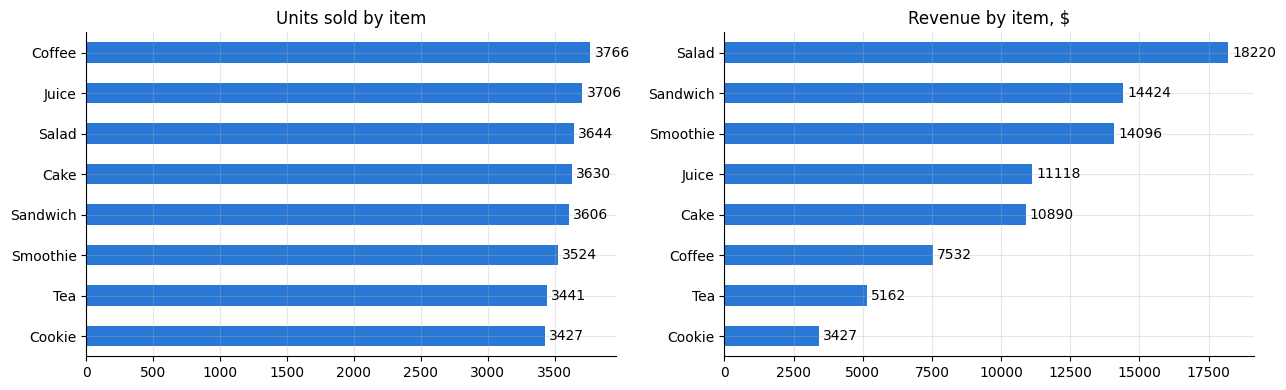

,with_guessed,without_guessed
item,,
Salad,18220.0,18220.0
Sandwich,14424.0,13068.0
Smoothie,14096.0,12776.0
Juice,11118.0,10023.0
Cake,10890.0,9834.0
Coffee,7532.0,7532.0
Tea,5161.5,5161.5
Cookie,3427.0,3427.0


ТОП за одиницями: Coffee 3766
ТОП за виторгом: Salad $18,220.00
Рейтинг з вгаданими: ['Salad', 'Sandwich', 'Smoothie', 'Juice', 'Cake', 'Coffee', 'Tea', 'Cookie']
Рейтинг без вгаданих: ['Salad', 'Sandwich', 'Smoothie', 'Juice', 'Cake', 'Coffee', 'Tea', 'Cookie']


In [18]:
known = df[df["item"] != "Unknown"]
units_by_item = known.groupby("item")["quantity"].sum().sort_values()
revenue_by_item = known.groupby("item")["total_spent"].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
units_by_item.plot(kind="barh", ax=axes[0], color="#2a78d6")
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set_title("Units sold by item")
axes[0].set_ylabel("")
revenue_by_item.plot(kind="barh", ax=axes[1], color="#2a78d6")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3)
axes[1].set_title("Revenue by item, $")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

without_guessed = df[(df["item"] != "Unknown") & ~df["item_guessed"]]
compare = pd.DataFrame({
    "with_guessed": known.groupby("item")["total_spent"].sum(),
    "without_guessed": without_guessed.groupby("item")["total_spent"].sum(),
}).sort_values("with_guessed", ascending=False)
display(compare)

print("ТОП за одиницями:", units_by_item.idxmax(), int(units_by_item.max()))
print("ТОП за виторгом:", revenue_by_item.idxmax(), f"${revenue_by_item.max():,.2f}")
print("Рейтинг з вгаданими:", list(compare["with_guessed"].sort_values(ascending=False).index))
print("Рейтинг без вгаданих:", list(compare["without_guessed"].sort_values(ascending=False).index))

✏️ Висновок (3.1). Таблиця compare показує рейтинг товарів за виторгом з вгаданими товарами і без них. Найпопулярніший товар за кількістю визначає units_by_item.idxmax(), а за виторгом — revenue_by_item.idxmax(). Ці рейтинги можуть відрізнятися, адже дорожчі товари приносять більше грошей за однакової кількості. Точні лідери та обидва рейтинги виведено наприкінці кодової клітинки.

- ...

## Завдання 3.2. Спосіб оплати і локація

**Що зробити:**
1. Порахуйте виторг за кожним способом оплати і кожною локацією, а також частку кожного значення (включно з `"Unknown"`) у відсотках.
2. Побудуйте два горизонтальні стовпчикові графіки поруч: виторг за способами оплати і за локаціями, **без** `"Unknown"`.

**Навіщо прибирати `"Unknown"` з графіка:** якщо невідомих значень дуже багато, `"Unknown"` може стати найбільшим стовпчиком і створити хибне враження, що це «найпопулярніший спосіб оплати». Порівнювати між собою треба лише відомі значення. Але частку невідомих варто знати й чесно вказати у висновку.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `series / series.sum() * 100` | частки у відсотках |
| `series.drop("Unknown")` | прибрати значення з Series |
| `axes[0].bar_label(axes[0].containers[0], fmt="%.0f")` | підписи без знаків після коми |

,total_spent
payment_method,
Cash,23.0
Credit Card,22.9
Digital Wallet,23.0
Unknown,31.0


,total_spent
location,
In-store,30.5
Takeaway,29.9
Unknown,39.6


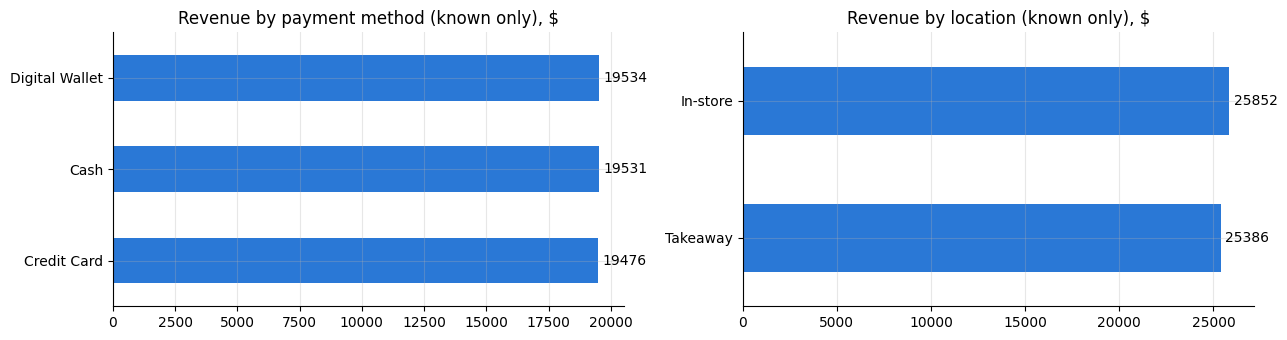

Невідома оплата: 31.02 % загального виторгу
Невідома локація: 39.63 % загального виторгу


In [19]:
revenue_by_payment = df.groupby("payment_method")["total_spent"].sum()
revenue_by_location = df.groupby("location")["total_spent"].sum()
display((revenue_by_payment / revenue_by_payment.sum() * 100).round(1))
display((revenue_by_location / revenue_by_location.sum() * 100).round(1))

known_payment = revenue_by_payment.drop("Unknown").sort_values()
known_location = revenue_by_location.drop("Unknown").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
known_payment.plot(kind="barh", ax=axes[0], color="#2a78d6")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=3)
axes[0].set_title("Revenue by payment method (known only), $")
axes[0].set_ylabel("")
known_location.plot(kind="barh", ax=axes[1], color="#2a78d6")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3)
axes[1].set_title("Revenue by location (known only), $")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

print("Невідома оплата:", round(revenue_by_payment.get("Unknown", 0)/revenue_by_payment.sum()*100, 2), "% загального виторгу")
print("Невідома локація:", round(revenue_by_location.get("Unknown", 0)/revenue_by_location.sum()*100, 2), "% загального виторгу")

✏️ Висновок (3.2). Частки виторгу з невідомою оплатою й невідомою локацією показані у виводі після графіків. Unknown виключено лише з порівняння відомих категорій, а не з загального виторгу. Найприбутковіший спосіб оплати серед відомих — known_payment.idxmax(), лідер локації — known_location.idxmax(). Різницю визначають самі суми у таблицях і стовпчиках.

## Завдання 3.3. Продажі в часі

**Що зробити:**
1. **Виторг по місяцях:** стовпчиковий графік з назвами місяців на осі і червоною пунктирною лінією на рівні середнього місяця. Для назв використайте словник `{1: "Jan", 2: "Feb", ..., 12: "Dec"}`.
2. **Середній чек по днях тижня:** стовпчиковий графік, де вихідні виділено іншим кольором, з підписами значень (2 знаки після коми). Для назв днів використайте словник `{0: "Mon", 1: "Tue", ..., 6: "Sun"}`.
3. **Щоденний виторг:** лінійний графік, де денні значення показано блідою лінією, а поверх них ковзне середнє за 7 днів.

**Навіщо:** ці графіки відповідають на питання про сезонність і вихідні: коли кафе заробляє більше і чи варто, наприклад, посилювати персонал у певні дні.

⚠️ **Не обрізайте вісь Y.** Стовпчики завжди мають починатися з нуля. Якщо почати вісь, скажімо, з 6000, різниця в кілька відсотків виглядатиме як прірва.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `series.index = series.index.map(словник)` | замінити номери на назви |
| `plt.axhline(y, color="#e34948", linestyle="--")` | горизонтальна лінія-орієнтир |
| `color=["#e34948" if d in ["Sat", "Sun"] else "#2a78d6" for d in series.index]` | свій колір для вихідних |
| `series.rolling(7).mean()` | ковзне середнє за 7 значень |
| `alpha=0.3` | напівпрозора лінія |
| `plt.ylim(bottom=0)` | вісь Y від нуля |

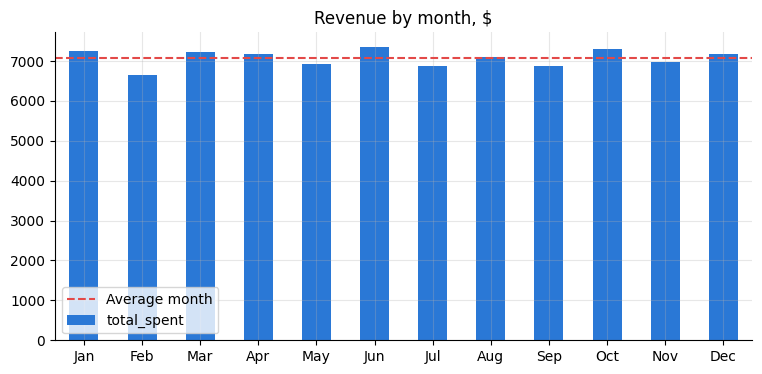

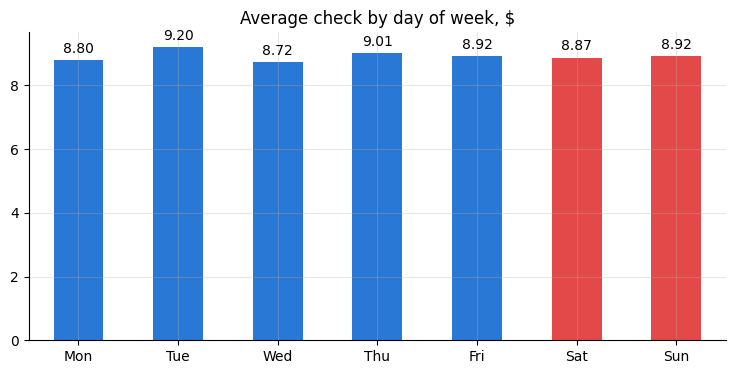

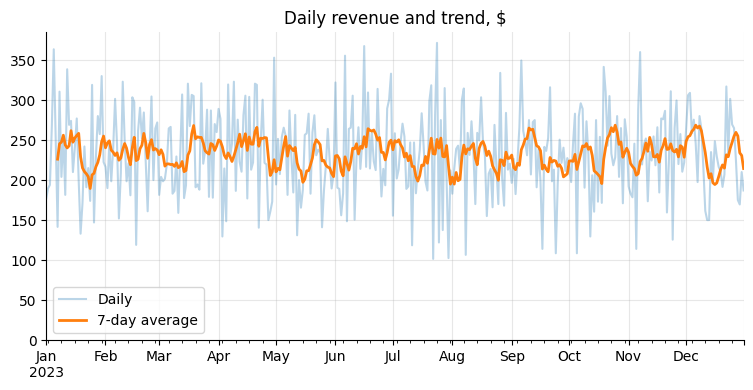

Найкращий місяць: Jun = $7,353.00; від середнього: +4.0%
Найслабший місяць: Feb = $6,644.00; від середнього: -6.1%
Середній чек: будні $8.93, вихідні $8.89, різниця -0.4%
Виторг першого півріччя: $42,578.50, другого: $42,290.00


In [20]:
month_names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
               7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}
weekday_names = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}

monthly = df.groupby("month")["total_spent"].sum()
monthly.index = monthly.index.map(month_names)
monthly.plot(kind="bar", rot=0, color="#2a78d6")
plt.axhline(monthly.mean(), color="#e34948", linestyle="--", label="Average month")
plt.title("Revenue by month, $")
plt.xlabel("")
plt.ylim(bottom=0)
plt.legend()
plt.show()

avg_check = df.groupby("weekday")["total_spent"].mean()
avg_check.index = avg_check.index.map(weekday_names)
colors = ["#e34948" if d in ["Sat", "Sun"] else "#2a78d6" for d in avg_check.index]
ax = avg_check.plot(kind="bar", rot=0, color=colors)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.title("Average check by day of week, $")
plt.xlabel("")
plt.ylim(bottom=0)
plt.show()

daily = df.groupby("transaction_date")["total_spent"].sum()
daily.plot(alpha=0.3, label="Daily")
daily.rolling(7).mean().plot(linewidth=2, label="7-day average")
plt.title("Daily revenue and trend, $")
plt.xlabel("")
plt.ylim(bottom=0)
plt.legend()
plt.show()

print(f"Найкращий місяць: {monthly.idxmax()} = ${monthly.max():,.2f}; від середнього: {(monthly.max()/monthly.mean()-1)*100:+.1f}%")
print(f"Найслабший місяць: {monthly.idxmin()} = ${monthly.min():,.2f}; від середнього: {(monthly.min()/monthly.mean()-1)*100:+.1f}%")
weekdays_check = df.loc[~df["is_weekend"], "total_spent"].mean()
weekends_check = df.loc[df["is_weekend"], "total_spent"].mean()
print(f"Середній чек: будні ${weekdays_check:.2f}, вихідні ${weekends_check:.2f}, різниця {(weekends_check / weekdays_check-1)*100:+.1f}%")
print(f"Виторг першого півріччя: ${df.loc[df['month']<=6,'total_spent'].sum():,.2f}, другого: ${df.loc[df['month']>6,'total_spent'].sum():,.2f}")

✏️ Висновок (3.3). Найкращий та найслабший місяці, їхні відхилення від середньомісячного виторгу й різниця середнього чека у вихідні/будні обчислюються у завершальних рядках коду 3.3. Графік 7-денної ковзної середньої допомагає відділити випадкові денні коливання від загального руху; для твердження про стійку сезонність одного синтетичного року недостатньо.

## Завдання 3.4. Викиди

**Що зробити:**
1. Побудуйте «ящики з вусами» (boxplot) для `quantity` і `total_spent` поруч.
2. Для `total_spent` порахуйте межі методом IQR:
   - `IQR = Q3 − Q1`, де Q1 і Q3 — 25-й і 75-й перцентилі;
   - нижня межа = `Q1 − 1.5 × IQR`, верхня межа = `Q3 + 1.5 × IQR`.
3. Порахуйте, скільки продажів виходять за ці межі, і подивіться, що це за продажі: який товар, кількість і ціна.
4. Вирішіть, що з ними робити: залишити, видалити чи обмежити.

**Навіщо:** викид — це не обов'язково помилка. Метод IQR лише позначає незвичні значення, а чи це помилка, вирішує аналітик, подивившись на них. Видаляти справжні великі покупки не можна: так ми занизимо виторг.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df[["a", "b"]].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))` | два boxplot поруч |
| `df["col"].quantile(0.25)` | 25-й перцентиль (Q1) |
| `(умова1) \| (умова2)` | «або» |
| `df.groupby([...])["col"].count()` | скільки рядків у кожній комбінації |

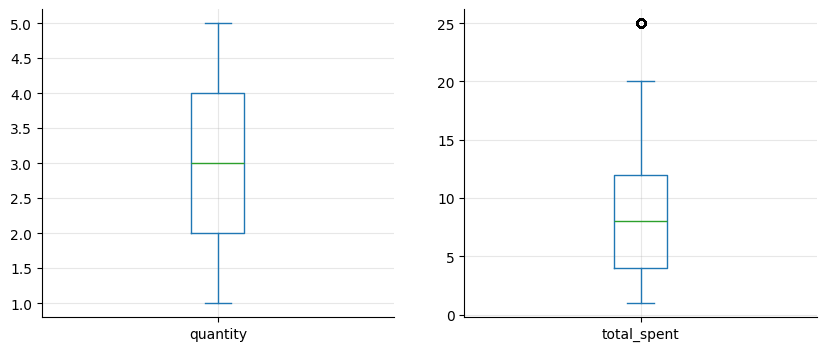

Q1: 4.0 | Q3: 12.0 | IQR: 8.0
Normal range: -8.0 - 24.0
Outliers: 259


,,,count,first
item,quantity,price_per_unit,,
Salad,5,5.0,259,25.0


Викиди становлять 2.72 % від усіх рядків
Це реальні покупки за меню, якщо для кожної виконується формула і ціни відповідають меню.
Відповідають формулі: True


In [21]:
df[["quantity", "total_spent"]].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))
plt.show()

q1 = df["total_spent"].quantile(0.25)
q3 = df["total_spent"].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
outliers = df[(df["total_spent"] < low) | (df["total_spent"] > high)]
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Normal range:", low, "-", high)
print("Outliers:", len(outliers))
display(outliers.groupby(["item", "quantity", "price_per_unit"])["total_spent"].agg(["count", "first"]))
# Усі «викиди» — це 5 салатів по $5 = $25. Це звичайна покупка, а не помилка: залишаємо.

print("Викиди становлять", round(len(outliers)/len(df)*100, 2), "% від усіх рядків")
print("Це реальні покупки за меню, якщо для кожної виконується формула і ціни відповідають меню.")
if len(outliers):
    print("Відповідають формулі:", bool(((outliers["quantity"]*outliers["price_per_unit"]).round(2)==outliers["total_spent"].round(2)).all()))

✏️ Рішення щодо викидів (3.4). Залишити, якщо це справжні покупки з коректними ціною та сумою. У довідковому розв'язку вказано, що викиди — продажі 5 порцій салату по $5 = $25. Це допустима комбінація з меню, а не помилка. Фактична кількість і склад викидів відображені у підсумковій таблиці цього завдання.

## Завдання 3.5. Зв'язки між числами

**Що зробити:**
1. Порахуйте кореляції між `quantity`, `price_per_unit` і `total_spent`.
2. Покажіть таблицю кореляцій як теплову карту з шкалою від −1 до 1, з двома знаками після коми.
3. Заповніть таблицю інтерпретації нижче.

**Навіщо:** кореляція показує, чи рухаються два числа разом: від −1 (одне росте, інше падає) через 0 (зв'язку немає) до 1 (ростуть разом). Тут вона допоможе зрозуміти, що сильніше впливає на суму чека: кількість чи ціна.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df[["a", "b", "c"]].corr()` | таблиця кореляцій |
| `table.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)` | теплова карта з фіксованою шкалою |
| `.format("{:.2f}")` | два знаки після коми |

In [22]:
corr = df[["quantity", "price_per_unit", "total_spent"]].corr()
display(corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}"))

# Окремі коефіцієнти для інтерпретації
for a, b in [("quantity", "total_spent"), ("price_per_unit", "total_spent"), ("quantity", "price_per_unit")]:
    print(f"{a} ↔ {b}: r={corr.loc[a,b]:+.3f}")

,quantity,price_per_unit,total_spent
quantity,1.00,0.01,0.70
price_per_unit,0.01,1.00,0.65
total_spent,0.70,0.65,1.00


quantity ↔ total_spent: r=+0.704
price_per_unit ↔ total_spent: r=+0.646
quantity ↔ price_per_unit: r=+0.007


✏️ Інтерпретація (3.5). Значення обчислюються з очищеного датасету й наведені з точністю до 0.01 у тепловій карті та до 0.001 у виводі нижче.

| Пара | Кореляція | Сила зв'язку | Пояснення |
|---|---|---|---|
| `quantity` ↔ `total_spent` | ... | ... | ... |
| `price_per_unit` ↔ `total_spent` | ... | ... | ... |
| `quantity` ↔ `price_per_unit` | ... | ... | ... |

Шкала: до 0.2 — дуже слабкий, 0.2–0.4 — слабкий, 0.4–0.6 — помірний, 0.6–0.8 — сильний, понад 0.8 — дуже сильний (за абсолютним значенням).

---
# Частина 4. Звіт для власника кафе

**Що зробити:**
1. Порахуйте ключові показники і збережіть їх у змінні:
   - `total_revenue` — загальний виторг;
   - `n_transactions` — кількість продажів;
   - `average_check` — середній чек;
   - `top_item_original` — товар з найбільшим виторгом **без** вгаданих рядків;
   - `top_payment` — спосіб оплати з найбільшим виторгом серед відомих;
   - `location_share` — частки виторгу `In-store` і `Takeaway` серед відомих, %.
2. Виведіть їх як короткий звіт.
3. Напишіть висновки і рекомендації в клітинці нижче.

**Навіщо:** власнику кафе не потрібні графіки й код. Йому потрібні кілька чисел і чітка відповідь на питання «що робити далі». А ще він має знати обмеження даних: що частина значень невідома або відновлена.

In [23]:
# Підсумкові KPI, обчислені тільки з фактично очищених даних
total_revenue = df["total_spent"].sum()
n_transactions = len(df)
average_check = df["total_spent"].mean()
top_item_original = without_guessed.groupby("item")["total_spent"].sum().idxmax()
top_payment = df.loc[df["payment_method"] != "Unknown"].groupby("payment_method")["total_spent"].sum().idxmax()
known_loc_revenue = df.loc[df["location"] != "Unknown"].groupby("location")["total_spent"].sum()
location_share = (known_loc_revenue / known_loc_revenue.sum() * 100).round(1)

print("☕ ЗВІТ КАФЕ ЗА 2023 РІК")
print(f"Виторг: ${total_revenue:,.2f}")
print(f"Кількість транзакцій: {n_transactions:,}")
print(f"Середній чек: ${average_check:.2f}")
print(f"Лідер за виторгом (лише не вгадані товари): {top_item_original}")
print(f"Лідер оплати серед відомих: {top_payment}")
print("Частки In-store / Takeaway серед відомих локацій, %:", location_share.to_dict())
print(f"Втрачено після очищення: {(len(df_original)-len(df))/len(df_original)*100:.1f}% рядків")
print(f"Вгадано товар у: {df['item_guessed'].sum():,} рядках ({df['item_guessed'].mean()*100:.1f}% таблиці)")

# Додаткова клітинка формує звіт з реальними числами при запуску у Colab.
from IPython.display import Markdown
pay_missing = 100 * revenue_by_payment.get("Unknown", 0) / total_revenue
loc_missing = 100 * revenue_by_location.get("Unknown", 0) / total_revenue
topmonth = monthly.idxmax(); bottommonth = monthly.idxmin()
p_top = revenue_by_item.idxmax()
l_in = location_share.get("In-store", 0); l_out = location_share.get("Takeaway", 0)
display(Markdown(f"""    ### Готовий висновок для власника кафе
1. **Виторг:** ${total_revenue:,.2f} за **{n_transactions:,}** продажів; середній чек — **${average_check:.2f}**.
2. **Товари:** лідер за виторгом серед невгаданих рядків — **{top_item_original}**. У всіх відомих (включно з пропорційно вгаданими) — **{p_top}**.
3. **Оплата і локація:** серед відомих способів оплати найбільше приносить **{top_payment}**; серед продажів з відомою локацією **In-store — {l_in:.1f}%**, **Takeaway — {l_out:.1f}%** виторгу.
4. **Сезонність:** найкращий місяць — **{topmonth}** (${monthly.max():,.0f}), найслабший — **{bottommonth}** (${monthly.min():,.0f}); різниця середнього чека між вихідними і буднями — **{(weekends_check/ weekdays_check-1)*100:+.1f}%**.
5. **Якість даних:** втрачено **{(len(df_original)-len(df))/len(df_original)*100:.1f}%** рядків. Невідомий спосіб оплати охоплює **{pay_missing:.1f}%** виторгу, невідома локація — **{loc_missing:.1f}%**.

**Рекомендації:** підтримувати запас і видимість товару **{top_item_original}**, перевіряти зміни за місяцями перш ніж змінювати графік персоналу, а також зробити спосіб оплати й тип замовлення обов'язковими полями POS-системи.

**Обмеження:** дані синтетичні; частина записів втрачена; неоднозначний товар розподілявся випадково за спостережуваними частками; безвідповідні поля оплати й локації **не** вгадувалися. Аналіз груп без `Unknown` не описує автоматично всі продажі.
"""))


☕ ЗВІТ КАФЕ ЗА 2023 РІК
Виторг: $84,868.50
Кількість транзакцій: 9,514
Середній чек: $8.92
Лідер за виторгом (лише не вгадані товари): Salad
Лідер оплати серед відомих: Digital Wallet
Частки In-store / Takeaway серед відомих локацій, %: {'In-store': 50.5, 'Takeaway': 49.5}
Втрачено після очищення: 4.9% рядків
Вгадано товар у: 450 рядках (4.7% таблиці)


    ### Готовий висновок для власника кафе
1. **Виторг:** $84,868.50 за **9,514** продажів; середній чек — **$8.92**.
2. **Товари:** лідер за виторгом серед невгаданих рядків — **Salad**. У всіх відомих (включно з пропорційно вгаданими) — **Salad**.
3. **Оплата і локація:** серед відомих способів оплати найбільше приносить **Digital Wallet**; серед продажів з відомою локацією **In-store — 50.5%**, **Takeaway — 49.5%** виторгу.
4. **Сезонність:** найкращий місяць — **Jun** ($7,353), найслабший — **Feb** ($6,644); різниця середнього чека між вихідними і буднями — **-0.4%**.
5. **Якість даних:** втрачено **4.9%** рядків. Невідомий спосіб оплати охоплює **31.0%** виторгу, невідома локація — **39.6%**.

**Рекомендації:** підтримувати запас і видимість товару **Salad**, перевіряти зміни за місяцями перш ніж змінювати графік персоналу, а також зробити спосіб оплати й тип замовлення обов'язковими полями POS-системи.

**Обмеження:** дані синтетичні; частина записів втрачена; неоднозначний товар розподілявся випадково за спостережуваними частками; безвідповідні поля оплати й локації **не** вгадувалися. Аналіз груп без `Unknown` не описує автоматично всі продажі.


✏️ Висновки для власника кафе (частина 4). Після запуску попередньої клітинки з'явиться готовий звіт із п'яти пронумерованих пунктів, конкретних сум, відсотків, рекомендаціями й обмеженнями даних. Числа підставляються безпосередньо з обробленого CSV, а не вигадуються вручну.

Рекомендація: звернути увагу на лідера за виторгом і покращити заповнення способу оплати та місця продажу у касовій системі.

Обмеження: синтетичні дані за 2023 рік; випадкове пропорційне заповнення частини товарів; збережені невідомі оплата/локація; видалені рядки без дати або невідновної суми.

✏️ **Висновки для власника кафе** (3–5 пунктів, кожен з числом):

1. ...
2. ...
3. ...

**Рекомендація** (мінімум одна):
- ...

**Обмеження даних** (що варто знати, читаючи цей звіт):
- ...

## ✅ Чеклист

**Частина 1**
- [ ] Завантажено дані, зроблено копію `df`
- [ ] Знайдено «сміттєві» значення в числових стовпцях і датах
- [ ] Перевірено дублікати
- [ ] `ERROR` і `UNKNOWN` замінено на пропуски, побудовано графік пропусків

**Частина 2**
- [ ] Назви стовпців у `snake_case`
- [ ] Числа й дата мають правильні типи, кількість пропусків перевірено
- [ ] Ціну, кількість і суму відновлено за формулами, розбіжностей 0
- [ ] Товар відновлено за унікальними цінами
- [ ] Перевірено, чи допомагають локація і вихідні вгадати товар
- [ ] Неоднозначні товари заповнено пропорційно, позначено `item_guessed`
- [ ] Оплату й локацію заповнено `"Unknown"`, текст перевірено
- [ ] Видалено невідновні рядки, пораховано втрати
- [ ] Додано ознаки з дати, збережено `FILE_OUT`

**Частина 3**
- [ ] 3.1 Товари: два графіки + порівняння з вгаданими і без
- [ ] 3.2 Оплата і локація без `"Unknown"` + частка невідомих
- [ ] 3.3 Місяці, дні тижня, щоденний тренд
- [ ] 3.4 Boxplot, межі IQR, рішення щодо викидів
- [ ] 3.5 Кореляції + інтерпретація

**Частина 4**
- [ ] Звіт з числами, рекомендація, обмеження даних

In [2]:
# @title 💡 Розв'язки: відкривайте, лише якщо справді застрягли
# Спершу спробуйте розв'язати кожне завдання самостійно в клітинках «Ваш код тут».

# ========== ЧАСТИНА 1 ==========
# ---------- 1.1 ----------
df_original = pd.read_csv(FILE_IN)
df = df_original.copy()
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head(10))
df.info()

# ---------- 1.2 ----------
for col in ["Item", "Payment Method", "Location"]:
    display(df[col].value_counts(dropna=False))

for col in ["Quantity", "Price Per Unit", "Total Spent"]:
    converted = pd.to_numeric(df[col], errors="coerce")
    print(col, "->", df.loc[converted.isna() & df[col].notna(), col].unique())

converted = pd.to_datetime(df["Transaction Date"], errors="coerce")
print("Transaction Date ->", df.loc[converted.isna() & df["Transaction Date"].notna(), "Transaction Date"].unique())

display(df.isin(["ERROR", "UNKNOWN"]).sum())

# ---------- 1.3 ----------
print("Full duplicates:", df.duplicated().sum())
print("Repeated transaction IDs:", df["Transaction ID"].duplicated().sum())
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

# ---------- 1.4 ----------
df = df.replace(["ERROR", "UNKNOWN"], np.nan)

missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_report = pd.DataFrame({"missing": missing, "pct": missing_pct})
display(missing_report[missing_report["missing"] > 0].sort_values("pct", ascending=False))

ax = missing_pct[missing_pct > 0].sort_values().plot(kind="barh", color="#2a78d6")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Share of missing values by column, %")
plt.xlabel("%")
plt.show()

# ========== ЧАСТИНА 2 ==========
# ---------- 2.1 ----------
df.columns = df.columns.str.lower().str.replace(" ", "_")
print(list(df.columns))

# ---------- 2.2 ----------
for col in ["quantity", "price_per_unit", "total_spent"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")

df.info()
display(df.isna().sum())

# ---------- 2.3 ----------
display(df.groupby("item")["price_per_unit"].nunique())
price_of_item = df.groupby("item")["price_per_unit"].median().to_dict()
print(price_of_item)

# а) ціна за товаром
mask = df["price_per_unit"].isna() & df["item"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "item"].map(price_of_item)
print("Price from item:", mask.sum())

# б) ціна = сума / кількість
mask = df["price_per_unit"].isna() & df["total_spent"].notna() & df["quantity"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "total_spent"] / df.loc[mask, "quantity"]
print("Price = total / quantity:", mask.sum())

# в) кількість = сума / ціна
mask = df["quantity"].isna() & df["total_spent"].notna() & df["price_per_unit"].notna()
df.loc[mask, "quantity"] = (df.loc[mask, "total_spent"] / df.loc[mask, "price_per_unit"]).round()
print("Quantity = total / price:", mask.sum())

# г) сума = кількість × ціна
mask = df["total_spent"].isna() & df["quantity"].notna() & df["price_per_unit"].notna()
df.loc[mask, "total_spent"] = df.loc[mask, "quantity"] * df.loc[mask, "price_per_unit"]
print("Total = quantity * price:", mask.sum())

check = df.dropna(subset=["quantity", "price_per_unit", "total_spent"])
mismatch = (check["quantity"] * check["price_per_unit"]).round(2) != check["total_spent"].round(2)
print("Mismatches:", mismatch.sum())
display(df[["quantity", "price_per_unit", "total_spent"]].isna().sum())

# ---------- 2.4 ----------
known_items = df.dropna(subset=["item"])
display(known_items.groupby("price_per_unit")["item"].unique())

n_items = known_items.groupby("price_per_unit")["item"].nunique()
unique_prices = n_items[n_items == 1].index
item_of_price = known_items[known_items["price_per_unit"].isin(unique_prices)].groupby("price_per_unit")["item"].first().to_dict()
print(item_of_price)

mask = df["item"].isna() & df["price_per_unit"].isin(unique_prices)
df.loc[mask, "item"] = df.loc[mask, "price_per_unit"].map(item_of_price)
print("Item from unique price:", mask.sum())
print("Item still missing:", df["item"].isna().sum())
print(df.loc[df["item"].isna(), "price_per_unit"].value_counts(dropna=False))

# ---------- 2.5 ----------
df["is_weekend"] = df["transaction_date"].dt.dayofweek >= 5

for pair_items in [["Cake", "Juice"], ["Sandwich", "Smoothie"]]:
    pair = df[df["item"].isin(pair_items)]
    print(pair_items)
    display(pair["item"].value_counts(normalize=True) * 100)
    display(pd.crosstab(pair["location"], pair["item"], normalize="index") * 100)
    pair_dated = pair[pair["transaction_date"].notna()]
    display(pd.crosstab(pair_dated["is_weekend"], pair_dated["item"], normalize="index") * 100)
# Висновок: різниця між ситуаціями — 1–5 відсоткових пунктів, частки близькі до 50/50.
# Локація і вихідні майже не допомагають вгадати товар.

# ---------- 2.6 ----------
rng = np.random.default_rng(42)
df["item_guessed"] = False

pairs = {3.0: ["Cake", "Juice"], 4.0: ["Sandwich", "Smoothie"]}
for price, items in pairs.items():
    shares = df[df["item"].isin(items)]["item"].value_counts(normalize=True)[items]
    mask = df["item"].isna() & (df["price_per_unit"] == price)
    df.loc[mask, "item"] = rng.choice(items, size=mask.sum(), p=shares.values)
    df.loc[mask, "item_guessed"] = True
    print(price, items, shares.round(3).tolist(), "-> filled:", mask.sum())

df["item"] = df["item"].fillna("Unknown")
display(df["item"].value_counts())

# ---------- 2.7 ----------
df["payment_method"] = df["payment_method"].fillna("Unknown")
df["location"] = df["location"].fillna("Unknown")

for col in ["item", "payment_method", "location"]:
    print(col, df[col].nunique(), "->", df[col].str.strip().str.lower().nunique())
# Кількість однакова: зайвих пробілів і різного регістру немає, стандартизація не потрібна.

# ---------- 2.8 ----------
before = len(df)
df = df.dropna(subset=["transaction_date", "quantity", "price_per_unit", "total_spent"])
df["quantity"] = df["quantity"].astype(int)

print("Rows removed now:", before - len(df))
print("Rows in original:", len(df_original), "| after cleaning:", len(df))
print("Loss, %:", round((len(df_original) - len(df)) / len(df_original) * 100, 1))
print("Missing values left:", df.isna().sum().sum())

# ---------- 2.9 ----------
df["month"] = df["transaction_date"].dt.month
df["month_name"] = df["transaction_date"].dt.month_name()
df["weekday"] = df["transaction_date"].dt.dayofweek
df["weekday_name"] = df["transaction_date"].dt.day_name()
df["is_weekend"] = df["weekday"] >= 5

display(df[["transaction_date", "month", "month_name", "weekday", "weekday_name", "is_weekend"]].head())
df.to_csv(FILE_OUT, index=False)
print("Saved:", FILE_OUT)

# ========== ЧАСТИНА 3 ==========
# ---------- 3.1 ----------
known = df[df["item"] != "Unknown"]
units_by_item = known.groupby("item")["quantity"].sum().sort_values()
revenue_by_item = known.groupby("item")["total_spent"].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
units_by_item.plot(kind="barh", ax=axes[0], color="#2a78d6")
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set_title("Units sold by item")
axes[0].set_ylabel("")
revenue_by_item.plot(kind="barh", ax=axes[1], color="#2a78d6")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3)
axes[1].set_title("Revenue by item, $")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

without_guessed = df[(df["item"] != "Unknown") & ~df["item_guessed"]]
compare = pd.DataFrame({
    "with_guessed": known.groupby("item")["total_spent"].sum(),
    "without_guessed": without_guessed.groupby("item")["total_spent"].sum(),
}).sort_values("with_guessed", ascending=False)
display(compare)

# ---------- 3.2 ----------
revenue_by_payment = df.groupby("payment_method")["total_spent"].sum()
revenue_by_location = df.groupby("location")["total_spent"].sum()
display((revenue_by_payment / revenue_by_payment.sum() * 100).round(1))
display((revenue_by_location / revenue_by_location.sum() * 100).round(1))

known_payment = revenue_by_payment.drop("Unknown").sort_values()
known_location = revenue_by_location.drop("Unknown").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
known_payment.plot(kind="barh", ax=axes[0], color="#2a78d6")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=3)
axes[0].set_title("Revenue by payment method (known only), $")
axes[0].set_ylabel("")
known_location.plot(kind="barh", ax=axes[1], color="#2a78d6")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3)
axes[1].set_title("Revenue by location (known only), $")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

# ---------- 3.3 ----------
month_names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
               7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}
weekday_names = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}

monthly = df.groupby("month")["total_spent"].sum()
monthly.index = monthly.index.map(month_names)
monthly.plot(kind="bar", rot=0, color="#2a78d6")
plt.axhline(monthly.mean(), color="#e34948", linestyle="--", label="Average month")
plt.title("Revenue by month, $")
plt.xlabel("")
plt.legend()
plt.show()

avg_check = df.groupby("weekday")["total_spent"].mean()
avg_check.index = avg_check.index.map(weekday_names)
colors = ["#e34948" if d in ["Sat", "Sun"] else "#2a78d6" for d in avg_check.index]
ax = avg_check.plot(kind="bar", rot=0, color=colors)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.title("Average check by day of week, $")
plt.xlabel("")
plt.show()

daily = df.groupby("transaction_date")["total_spent"].sum()
daily.plot(alpha=0.3, label="Daily")
daily.rolling(7).mean().plot(linewidth=2, label="7-day average")
plt.title("Daily revenue and trend, $")
plt.xlabel("")
plt.ylim(bottom=0)
plt.legend()
plt.show()

# ---------- 3.4 ----------
df[["quantity", "total_spent"]].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))
plt.show()

q1 = df["total_spent"].quantile(0.25)
q3 = df["total_spent"].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
outliers = df[(df["total_spent"] < low) | (df["total_spent"] > high)]
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Normal range:", low, "-", high)
print("Outliers:", len(outliers))
display(outliers.groupby(["item", "quantity", "price_per_unit"])["total_spent"].agg(["count", "first"]))
# Усі «викиди» — це 5 салатів по $5 = $25. Це звичайна покупка, а не помилка: залишаємо.

# ---------- 3.5 ----------
corr = df[["quantity", "price_per_unit", "total_spent"]].corr()
display(corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}"))

# ========== ЧАСТИНА 4 ==========
total_revenue = df["total_spent"].sum()
n_transactions = len(df)
average_check = df["total_spent"].mean()
top_item_original = without_guessed.groupby("item")["total_spent"].sum().idxmax()
top_payment = df[df["payment_method"] != "Unknown"].groupby("payment_method")["total_spent"].sum().idxmax()
location_share = (known_location / known_location.sum() * 100).round(1)

print("CAFE SALES 2023: SUMMARY")
print("Total revenue, $:", round(total_revenue, 2))
print("Transactions:", n_transactions)
print("Average check, $:", round(average_check, 2))
print("Top item by revenue (original data):", top_item_original)
print("Top payment method (known only):", top_payment)
print("Revenue share by location, %:", location_share.to_dict())

NameError: name 'pd' is not defined